# 00 · Data check: quarterly revenue from SEC filings

This notebook checks `data/processed/revenue_quarterly.csv`, built by `src/build_quarterly.py`, before we forecast anything.

Five checks:
1. How many quarters each company has, and whether any are missing.
2. Whether the four quarters add up to the full year that the company reported (within 0.5 %).
3. How often a quarter's first-reported revenue differs from its latest value (restatements).
4. How long after a quarter ended its revenue first became public. This matters for the "no future information" rule.
5. A chart of revenue per company.

## Setup
Load the table. `period_end` and `first_filed_date` are read as dates.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

# The notebook lives in notebooks/, so the project folder is one level up.
PROJECT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))     # lets us reuse code from src/

q = pd.read_csv(PROJECT / "data" / "processed" / "revenue_quarterly.csv",
                parse_dates=["period_end", "first_filed_date"])
q["label"] = q["fiscal_year"].astype(str) + " Q" + q["fiscal_quarter"].astype(str)
print(q.shape)
q.head()

(222, 10)


,company,fiscal_year,fiscal_quarter,period_end,revenue_first_reported,revenue_latest,first_filed_date,source_tag,q4_derived,label
0,Mattel,2008,2,2008-06-30,1112431000,1112431000,2009-07-29,SalesRevenueNet,False,2008 Q2
1,Mattel,2008,3,2008-09-30,1946315000,1946315000,2009-10-28,SalesRevenueNet,False,2008 Q3
2,Mattel,2008,4,2008-12-31,1939957000,1939957000,2010-02-24,SalesRevenueNet,True,2008 Q4
3,Mattel,2009,1,2009-03-31,785646000,785646000,2010-04-28,SalesRevenueNet,False,2009 Q1
4,Mattel,2009,2,2009-06-30,898197000,898197000,2009-07-29,SalesRevenueNet,False,2009 Q2


## 1. Quarters per company
We count the quarters and list any missing between the first and the last one. A quarter's position is `year × 4 + quarter`, so consecutive quarters differ by exactly 1.

"Q4 reported" and "Q4 derived" say how each Q4's *first-reported* value was obtained: from a 3-month Q4 value in a filing, or as full year − Q1 − Q2 − Q3 (or full year − Jan–Sep), whichever was public first.

In [2]:
q["position"] = q["fiscal_year"] * 4 + q["fiscal_quarter"]

def gaps(g):
    have = set(g["position"])
    missing = [p for p in range(g["position"].min(), g["position"].max() + 1) if p not in have]
    return ", ".join(f"{(p - 1) // 4} Q{(p - 1) % 4 + 1}" for p in missing) or "none"

per_company = q.groupby("company", sort=False).apply(lambda g: pd.Series({
    "quarters": len(g),
    "first": g["label"].iloc[0],
    "last": g["label"].iloc[-1],
    "gaps": gaps(g),
    "Q4 reported": int((~g["q4_derived"] & (g["fiscal_quarter"] == 4)).sum()),
    "Q4 derived": int(g["q4_derived"].sum()),
}), include_groups=False)
per_company

,quarters,first,last,gaps,Q4 reported,Q4 derived
company,,,,,,
Mattel,74,2008 Q2,2026 Q3,none,10,8
Caterpillar,74,2008 Q2,2026 Q3,none,11,7
Alphabet,74,2008 Q2,2026 Q3,none,0,18


**What this shows:** each company has all 74 quarters from 2008 Q2 to 2026 Q3, with no gaps. The series start in 2008 Q2 because companies began tagging their filings in machine-readable XBRL in 2009, and those filings include the same quarter of the year before for comparison. Alphabet never reports Q4 on its own, so all 18 of its Q4s are derived. Mattel and Caterpillar report Q4 directly in about 10 years each.

## 2. Do four quarters add up to the full year?
We take each company's full-year revenue from the raw filings (same tags as the quarterly table), add up Q1–Q4, and compare. A difference above 0.5 % is a failure.

There's a catch: when the latest Q4 is *derived* (full year − Q1 − Q2 − Q3), the four quarters add up to the year automatically. They can still fail if the full year was restated later and the quarters never were. So the real test is the years where a Q4 value was reported on its own. We show both groups.

In [3]:
from build_quarterly import load_facts, prepare

facts = prepare(load_facts())
years = facts[facts["kind"] == "year"].sort_values(["filed", "accn"])
full_year = (years.groupby(["company", "fiscal_year"])["val"]
                  .agg(year_first="first", year_latest="last").reset_index())
direct_q4 = (facts[(facts["kind"] == "quarter") & (facts["fiscal_quarter"] == 4)]
             [["company", "fiscal_year"]].drop_duplicates().assign(q4_direct=True))

complete = q.groupby(["company", "fiscal_year"]).filter(lambda g: len(g) == 4)
sums = (complete.groupby(["company", "fiscal_year"], sort=False)
                .agg(quarters_latest=("revenue_latest", "sum")).reset_index()
                .merge(full_year, on=["company", "fiscal_year"], how="left")
                .merge(direct_q4, on=["company", "fiscal_year"], how="left"))
sums["q4_direct"] = sums["q4_direct"].eq(True)        # missing -> False
sums["diff_%"] = 100 * (sums["quarters_latest"] / sums["year_latest"] - 1)
sums["fail"] = sums["diff_%"].abs() > 0.5
sums["Q4"] = sums["q4_direct"].map({True: "Q4 reported (real test)", False: "Q4 derived"})

print("Years with all 4 quarters:", len(sums))
display(sums.groupby(["company", "Q4"], sort=False)
            .agg(years=("fail", "size"), failures=("fail", "sum"),
                 largest_diff_pct=("diff_%", lambda s: s.abs().max())).round(3))
print("Failures:")
sums[sums["fail"]]

Years with all 4 quarters: 51


years  failures  largest_diff_pct
company     Q4                                                        
Mattel      Q4 reported (real test)     11         0             0.064
            Q4 derived                   6         0             0.000
Caterpillar Q4 reported (real test)     14         0             0.000
            Q4 derived                   3         0             0.000
Alphabet    Q4 derived                  17         1             8.984

Failures:


,company,fiscal_year,quarters_latest,year_first,year_latest,q4_direct,diff_%,fail,Q4
37,Alphabet,2012,50175000000,50175000000,46039000000,False,8.983688,True,Q4 derived


**What this shows:** in 50 of the 51 complete years, the four quarters add up to the reported full year within 0.5 %. The real test (years with a directly reported Q4: 11 for Mattel, 14 for Caterpillar) passes with at most 0.06 % difference. The one failure is Alphabet 2012. In 2015 Google restated full-year 2012 to remove Motorola Mobility, but it never restated the 2012 quarters. So the quarters add up to the original \$50.2 bn, not the restated \$46.0 bn. This is a real gap in the filings, not a coding error.

## 3. First reported vs latest
`revenue_first_reported` is what an analyst saw at the time; `revenue_latest` is the value after any later restatement. How often do they differ, and by how much?

In [4]:
q["revision_%"] = 100 * (q["revenue_latest"] / q["revenue_first_reported"] - 1)
q["revised"] = q["revenue_latest"] != q["revenue_first_reported"]

display(q.groupby("company", sort=False).agg(
    quarters=("revised", "size"),
    revised=("revised", "sum"),
    revised_over_half_pct=("revision_%", lambda s: (s.abs() > 0.5).sum()),
    largest_abs_pct=("revision_%", lambda s: s.abs().max()),
).round(2))

print("The 12 largest revisions:")
cols = ["company", "label", "revenue_first_reported", "revenue_latest", "revision_%", "q4_derived"]
q.loc[q["revision_%"].abs().sort_values(ascending=False).index[:12], cols].round(2)

,quarters,revised,revised_over_half_pct,largest_abs_pct
company,,,,
Mattel,74,5,0,0.47
Caterpillar,74,0,0,0.00
Alphabet,74,8,5,7.65


The 12 largest revisions:


,company,label,revenue_first_reported,revenue_latest,revision_%,q4_derived
169,Alphabet,2013 Q3,14893000000,13754000000,-7.65,False
167,Alphabet,2013 Q1,13969000000,12951000000,-7.29,False
168,Alphabet,2013 Q2,14105000000,13107000000,-7.08,False
170,Alphabet,2013 Q4,16858000000,15707000000,-6.83,True
164,Alphabet,2012 Q2,12214000000,11807000000,-3.33,False
40,Mattel,2018 Q2,840748000,844706000,0.47,False
49,Mattel,2020 Q3,1631691000,1636464000,0.29,False
38,Mattel,2017 Q4,1610873000,1606915000,-0.25,False
35,Mattel,2017 Q1,735618000,737418000,0.24,False
36,Mattel,2017 Q2,974477000,976177000,0.17,False


**What this shows:** Caterpillar never revised a quarter. Mattel revised 5, all by less than 0.5 %, mostly through an amended 10-K for 2017 filed in November 2019. Alphabet's large revisions are all in 2012–2013: Google removed the Motorola businesses it sold in 2013–2014 from past revenue, which lowered the 2013 quarters by about 7 %. So for Alphabet, first-reported and latest are different series in those years. That's why forecasts must be trained on first-reported values.

## 4. When did each quarter's revenue first become public?
`first_filed_date` − `period_end` = the number of days before the number was in an SEC filing. In a rolling forecast, a quarter can be used only after this date.

In [5]:
q["days_to_public"] = (q["first_filed_date"] - q["period_end"]).dt.days
q["era"] = pd.cut(q["fiscal_year"], [2007, 2009, 2026], labels=["2008-2009", "2010 onwards"])
display(q.groupby(["company", "era"], sort=False, observed=True)["days_to_public"]
         .describe()[["count", "min", "50%", "max"]].rename(columns={"50%": "median"}))
print("Quarters that took more than 100 days:")
q.loc[q["days_to_public"] > 100, ["company", "label", "period_end", "first_filed_date", "days_to_public", "q4_derived"]]

count   min  median    max
company     era                                     
Mattel      2008-2009       7.0  28.0   393.0  420.0
            2010 onwards   67.0  20.0    30.0   75.0
Caterpillar 2008-2009       7.0  30.0   395.0  415.0
            2010 onwards   67.0  30.0    35.0   57.0
Alphabet    2008-2009       7.0  35.0   400.0  408.0
            2010 onwards   67.0  23.0    29.0  389.0

Quarters that took more than 100 days:


,company,label,period_end,first_filed_date,days_to_public,q4_derived
0,Mattel,2008 Q2,2008-06-30,2009-07-29,394,False
1,Mattel,2008 Q3,2008-09-30,2009-10-28,393,False
2,Mattel,2008 Q4,2008-12-31,2010-02-24,420,True
3,Mattel,2009 Q1,2009-03-31,2010-04-28,393,False
74,Caterpillar,2008 Q2,2008-06-30,2009-08-12,408,False
75,Caterpillar,2008 Q3,2008-09-30,2009-10-30,395,False
76,Caterpillar,2008 Q4,2008-12-31,2010-02-19,415,True
77,Caterpillar,2009 Q1,2009-03-31,2010-05-03,398,False
148,Alphabet,2008 Q2,2008-06-30,2009-08-04,400,False
149,Alphabet,2008 Q3,2008-09-30,2009-11-04,400,False


**What this shows:** from 2010 onwards, revenue was public within about a month of the quarter's end (median 29–35 days; at most 75 days, except Alphabet 2012). The 2008–early 2009 quarters show about 400 days because they first appear in XBRL only as last year's comparison figures. Their real announcement was earlier, but we use the XBRL date. That's safe for the no-future-information rule, just conservative. Alphabet 2012 Q3 is late because Google's original Q3 2012 10-Q contains only the January–September total in the SEC data, not the 3-month figure. 2012 Q4 waits for it too.

## 5. Revenue per company
One chart per company, in $ billions, each with its own scale (the companies differ a lot in size). The blue line is the latest value. Orange dots mark first-reported values where they differ from the latest by more than 0.5 %.

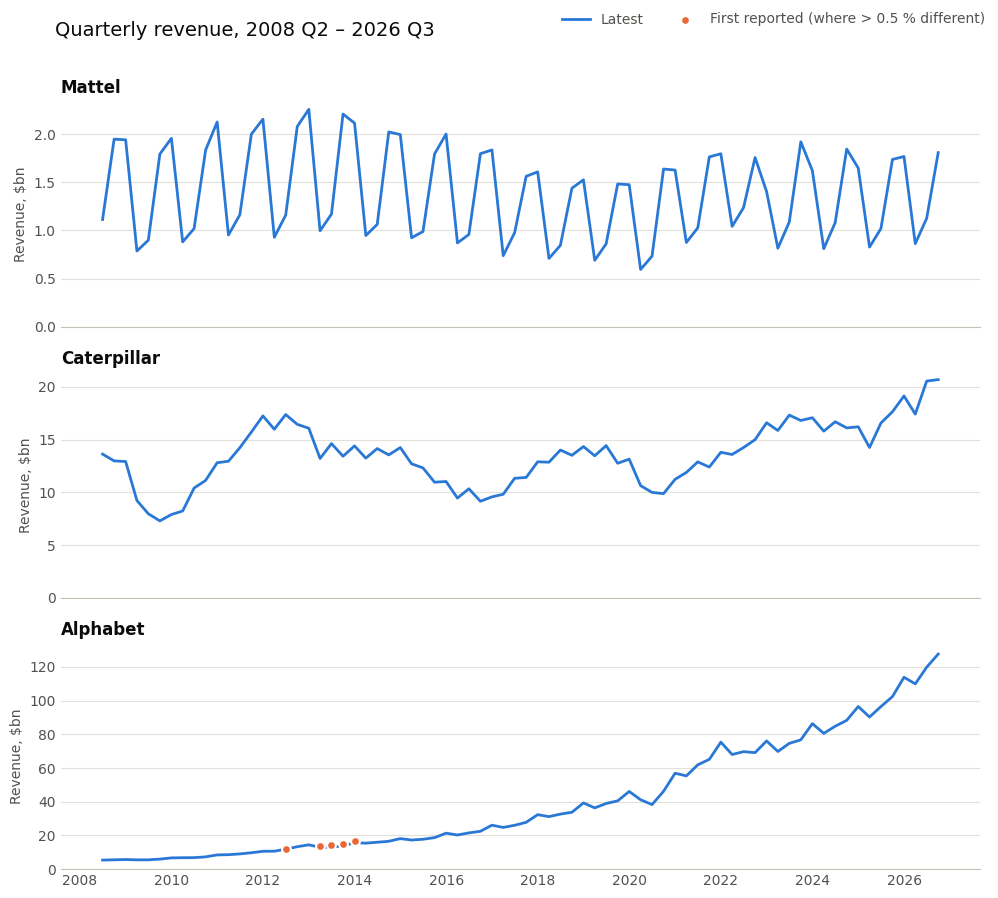

In [6]:
BLUE, ORANGE = "#2a78d6", "#eb6834"      # default palette slots 1 and 2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, (company, g) in zip(axes, q.groupby("company", sort=False)):
    ax.plot(g["period_end"], g["revenue_latest"] / 1e9, color=BLUE, lw=2, label="Latest")
    big = g[g["revision_%"].abs() > 0.5]
    ax.scatter(big["period_end"], big["revenue_first_reported"] / 1e9, s=40, color=ORANGE,
               edgecolor="white", linewidth=1.5, zorder=3,
               label="First reported (where > 0.5 % different)")
    ax.set_title(company, loc="left", color=INK, fontsize=12, fontweight="bold")
    ax.set_ylabel("Revenue, $bn", color=MUTED)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.tick_params(colors=MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="upper right", ncol=2, labelcolor=MUTED)
fig.suptitle("Quarterly revenue, 2008 Q2 – 2026 Q3", x=0.06, ha="left", color=INK, fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

**What this shows:** Mattel has a strong yearly pattern: Q3 and Q4 (holiday shipments to stores) are about twice Q1, with a slow decline from 2013 to 2019. Caterpillar follows the economic cycle: a deep drop in 2009, a peak in 2012, slumps in 2016 and 2020, and new highs in 2026. Alphabet grows almost every quarter and is about 24 times larger than in 2008. The orange dots (the 2012–2013 Motorola restatements) are small on this scale.

## Summary

The table is complete and consistent: 74 quarters per company, no gaps, and quarters that add up to the reported full year, apart from one explained case (Alphabet 2012).

Three things to carry into forecasting:
1. **Train on `revenue_first_reported`, and only from its `first_filed_date`.** That's what an FP&A analyst actually knew.
2. **Alphabet 2012–2013:** first-reported and latest differ by up to 7.6 % because of the Motorola restatements. A model scored against latest values would be judged on numbers nobody had at the time.
3. **2008–2009:** these quarters only became public in XBRL a year late, so the first fair forecast origin is around 2010.